# Handwritten Digit Classification (MNIST)

A simple CNN that looks at a 28x28 picture of a handwritten digit and tells which digit (0-9) it is.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Conv2D, MaxPool2D, Flatten, Dropout, BatchNormalization
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix

## Loading the data

In [2]:
from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


## Looking at the data

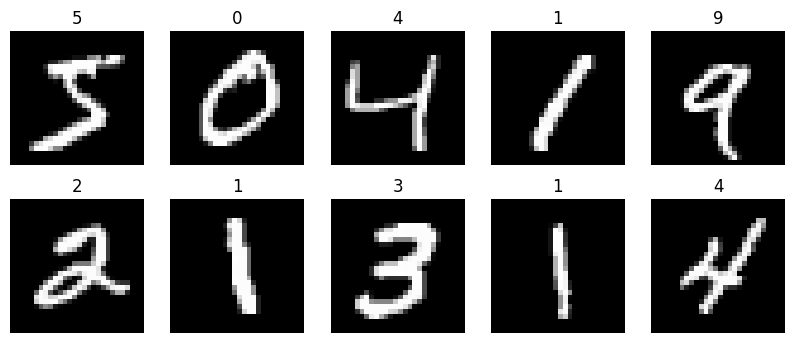

In [3]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(y_train[i])
    plt.axis('off')
plt.show()

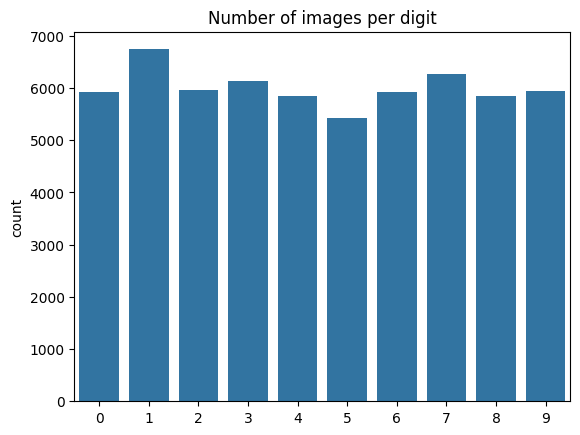

In [4]:
sns.countplot(x=y_train)
plt.title('Number of images per digit')
plt.show()

## Preprocessing

- Pixels go from 0 to 255, so I divide by 255 to get values between 0 and 1.
- Conv2D wants a channel dimension, the images are grayscale so it's 1 channel: `(28, 28)` → `(28, 28, 1)`.
- Labels are turned into one-hot vectors, e.g. `3` → `[0,0,0,1,0,0,0,0,0,0]`.

In [5]:
x_train = x_train / 255
x_test = x_test / 255

x_train = x_train.reshape(60000, 28, 28, 1)
x_test = x_test.reshape(10000, 28, 28, 1)

y_cat_train = to_categorical(y_train, 10)
y_cat_test = to_categorical(y_test, 10)

print(x_train.shape, y_cat_train.shape)

(60000, 28, 28, 1) (60000, 10)


## Building the model

In [6]:
model = Sequential()
model.add(Input(shape=(28, 28, 1)))

model.add(Conv2D(filters=32, kernel_size=(4, 4), activation='relu'))
model.add(MaxPool2D(pool_size=(2, 2)))

model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dense(10, activation='softmax'))

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

In [7]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 25, 25, 32)     │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 591,786 (2.26 MB)

 Trainable params: 591,786 (2.26 MB)

 Non-trainable params: 0 (0.00 B)

## Training

10% of the training images are kept for validation. The test set is only used at the end.

In [8]:
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

history = model.fit(x_train, y_cat_train,
                    epochs=10,
                    validation_split=0.1,
                    callbacks=[early_stop])

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 6ms/step - accuracy: 0.9554 - loss: 0.1478 - val_accuracy: 0.9853 - val_loss: 0.0539
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9856 - loss: 0.0480 - val_accuracy: 0.9892 - val_loss: 0.0395
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9902 - loss: 0.0310 - val_accuracy: 0.9877 - val_loss: 0.0496
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9933 - loss: 0.0211 - val_accuracy: 0.9872 - val_loss: 0.0518


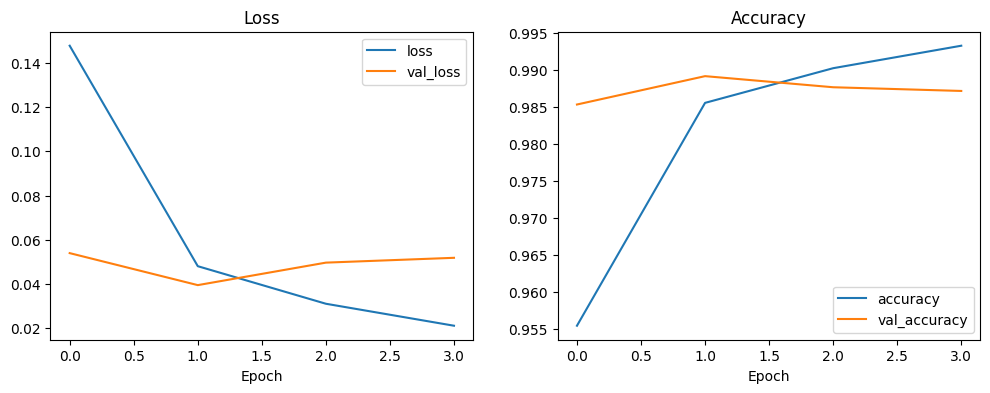

In [9]:
losses = pd.DataFrame(history.history)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
losses[['loss', 'val_loss']].plot(ax=ax[0], title='Loss')
losses[['accuracy', 'val_accuracy']].plot(ax=ax[1], title='Accuracy')
ax[0].set_xlabel('Epoch')
ax[1].set_xlabel('Epoch')
plt.show()

## Evaluating on the test set

In [10]:
test_loss, test_acc = model.evaluate(x_test, y_cat_test, verbose=0)
print('Test accuracy:', round(test_acc, 4))

Test accuracy: 0.986


In [11]:
predictions = model.predict(x_test).argmax(axis=-1)

print(classification_report(y_test, predictions))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.97      0.99      0.98       892
           6       0.99      0.97      0.98       958
           7       0.98      1.00      0.99      1028
           8       0.99      0.98      0.98       974
           9       0.99      0.96      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



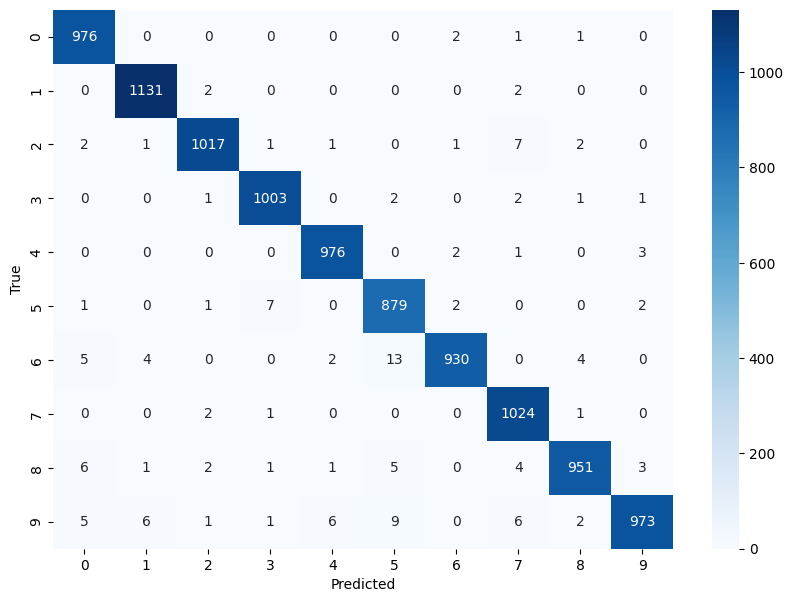

In [12]:
plt.figure(figsize=(10, 7))
sns.heatmap(confusion_matrix(y_test, predictions), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

## Predicting a single image

In [13]:
def predict_image(index):
    img = x_test[index]
    pred = model.predict(img.reshape(1, 28, 28, 1), verbose=0).argmax(axis=-1)[0]
    plt.imshow(img.reshape(28, 28), cmap='gray')
    plt.title(f'Predicted: {pred}   True: {y_test[index]}')
    plt.axis('off')
    plt.show()

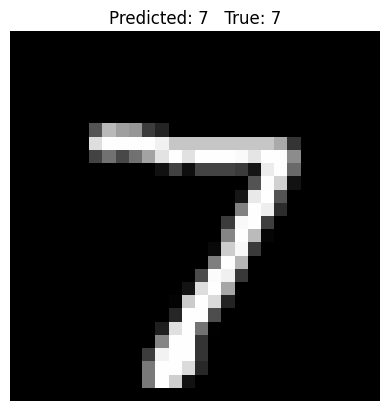

In [14]:
predict_image(0)

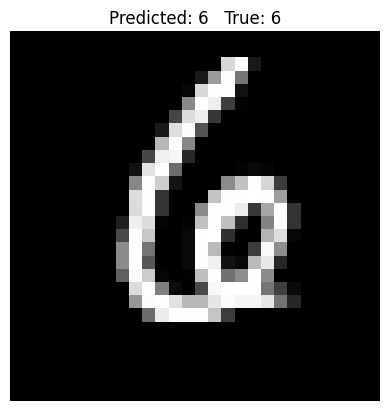

In [15]:
predict_image(123)